<a href="https://colab.research.google.com/github/RachmadAprisandhy/PBL_Kelompok3/blob/Zacky/Klasifikasi_Grading_Pisang_CNN_200foto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Langkah 1 — Hubungkan Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive berhasil dihubungkan.")

Mounted at /content/drive
Google Drive berhasil dihubungkan.


Langkah 2 — Memeriksa Folder Dataset

In [ ]:
import os

folder_dataset = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Banana Images/Synthetic Dataset"
)

print("Folder dataset ditemukan:", os.path.exists(folder_dataset))

if os.path.exists(folder_dataset):
    print("\nIsi folder:")
    for nama in sorted(os.listdir(folder_dataset)):
        print("-", nama)
else:
    print("\nFolder belum ditemukan. Periksa kembali path Google Drive.")

Folder dataset ditemukan: True

Isi folder:
- test
- train


Langkah 3 — Memeriksa Kelas dan Jumlah Gambar

In [ ]:
import os

folder_dataset = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Banana Images/Synthetic Dataset"
)

ekstensi_gambar = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

for bagian in ["train", "test"]:
    folder_bagian = os.path.join(folder_dataset, bagian)

    print(f"\n{'=' * 15} {bagian.upper()} {'=' * 15}")

    if not os.path.isdir(folder_bagian):
        print("Folder tidak ditemukan!")
        continue

    for kelas in sorted(os.listdir(folder_bagian)):
        folder_kelas = os.path.join(folder_bagian, kelas)

        if not os.path.isdir(folder_kelas):
            continue

        jumlah = 0

        for root, dirs, files in os.walk(folder_kelas):
            jumlah += sum(
                1 for nama in files
                if nama.lower().endswith(ekstensi_gambar)
            )

        print(f"{kelas}: {jumlah} gambar")


=============== TRAIN ===============
Ripeness A: 13243 gambar

=============== TEST ===============
Ripeness A: 8065 gambar
Ripeness B: 8064 gambar
Ripeness C: 8065 gambar
Ripeness D: 8064 gambar


Langkah 4 — Memeriksa Folder Dataset Pilihan

In [ ]:
import os

folder_utama = "/content/drive/MyDrive/Dataset PBL"

for root, dirs, files in os.walk(folder_utama):
    level = root.replace(folder_utama, "").count(os.sep)

    # Batasi tampilan agar output tidak terlalu panjang
    if level > 5:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    gambar = [
        f for f in files
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    if gambar:
        print(f"{indent}    Jumlah gambar: {len(gambar)}")
        print(f"{indent}    Contoh nama: {sorted(gambar)[:5]}")


Dataset PBL/
    Banana Images/
        Real Dataset/
            train/
                Class A/
                    Jumlah gambar: 857
                    Contoh nama: ['0 (2).png', '0.png', '1.png', '1000.png', '1001.png']
                Class D/
                    Jumlah gambar: 415
                    Contoh nama: ['1.png', '10.png', '100.png', '101.png', '103.png']
                Class B/
                    Jumlah gambar: 490
                    Contoh nama: ['0.png', '1.png', '101 (2).png', '101.png', '102.png']
                Class C/
                    Jumlah gambar: 335
                    Contoh nama: ['104.png', '11.png', '118.png', '123.png', '125 (2).png']
            test/
                Class A/
                    Jumlah gambar: 286
                    Contoh nama: ['10.png', '1011.png', '1021.png', '1022.png', '1023.png']
                Class B/
                    Jumlah gambar: 163
                    Contoh nama: ['10.png', '108 (2).png', '108.png', '109.pn

Langkah 5 — Memeriksa gambar setiap kelas

In [ ]:
import os

folder_test = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Banana Images/Synthetic Dataset/test"
)

kelas = ["Ripeness A", "Ripeness B", "Ripeness C", "Ripeness D"]
ekstensi = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

for nama_kelas in kelas:
    folder_kelas = os.path.join(
        folder_test, nama_kelas, "1 banana"
    )

    print(f"\n{nama_kelas}")

    if not os.path.isdir(folder_kelas):
        print("Folder tidak ditemukan!")
        continue

    gambar = sorted([
        nama for nama in os.listdir(folder_kelas)
        if nama.lower().endswith(ekstensi)
    ])

    print("Jumlah gambar:", len(gambar))
    print("Contoh nama:", gambar[:5])


Ripeness A
Jumlah gambar: 2017
Contoh nama: ['1.png', '10.png', '11.png', '12.png', '13.png']

Ripeness B
Jumlah gambar: 2016
Contoh nama: ['1.png', '10.png', '11.png', '12.png', '13.png']

Ripeness C
Jumlah gambar: 2015
Contoh nama: ['1.png', '10.png', '11.png', '12.png', '13.png']

Ripeness D
Jumlah gambar: 2016
Contoh nama: ['1.png', '10.png', '11.png', '12.png', '13.png']


Langkah 6 — Memeriksa 50 gambar pilihan

In [ ]:
import os

folder = "/content/banana_sample"

print("Struktur folder dan gambar:\n")

for root, dirs, files in os.walk(folder):
    level = root.replace(folder, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for nama in sorted(files):
        if nama.lower().endswith((".png", ".jpg", ".jpeg")):
            print(f"{indent}    {nama}")

print("\nPemeriksaan selesai.")

Struktur folder dan gambar:


Pemeriksaan selesai.


In [ ]:
import os

folder_test = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Banana Images/Synthetic Dataset/test"
)

kelas = ["Ripeness A", "Ripeness B", "Ripeness C", "Ripeness D"]

for nama_kelas in kelas:
    folder_kelas = os.path.join(
        folder_test, nama_kelas, "1 banana"
    )

    print(f"\n===== {nama_kelas} =====")

    ditemukan = 0
    tidak_ditemukan = []

    for nomor in range(1, 51):
        nama_file = f"{nomor}.png"
        path_gambar = os.path.join(folder_kelas, nama_file)

        if os.path.isfile(path_gambar):
            ditemukan += 1
        else:
            tidak_ditemukan.append(nama_file)

    print(f"Gambar ditemukan: {ditemukan}/50")

    if tidak_ditemukan:
        print("Gambar yang belum ditemukan:", tidak_ditemukan)



===== Ripeness A =====
Gambar ditemukan: 50/50

===== Ripeness B =====
Gambar ditemukan: 50/50

===== Ripeness C =====
Gambar ditemukan: 50/50

===== Ripeness D =====
Gambar ditemukan: 50/50


Langkah 7 — Menyalin dan memberi nama folder Grade A–D

In [ ]:
import os
import shutil

folder_asal = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Banana Images/Synthetic Dataset/test"
)

folder_tujuan = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Dataset Pisang 200 Gambar"
)

pemetaan_kelas = {
    "Ripeness A": "Grade A",
    "Ripeness B": "Grade B",
    "Ripeness C": "Grade C",
    "Ripeness D": "Grade D"
}

for kelas_asal, kelas_tujuan in pemetaan_kelas.items():
    sumber = os.path.join(folder_asal, kelas_asal, "1 banana")
    tujuan = os.path.join(folder_tujuan, kelas_tujuan)

    os.makedirs(tujuan, exist_ok=True)

    jumlah = 0

    for nomor in range(1, 51):
        nama_file = f"{nomor}.png"
        path_sumber = os.path.join(sumber, nama_file)
        path_tujuan = os.path.join(tujuan, nama_file)

        if os.path.isfile(path_sumber):
            shutil.copy2(path_sumber, path_tujuan)
            jumlah += 1

    print(f"{kelas_tujuan}: {jumlah} gambar disalin")

print("\nSelesai membuat dataset pilihan.")
print("Lokasi:", folder_tujuan)


Grade A: 50 gambar disalin
Grade B: 50 gambar disalin
Grade C: 50 gambar disalin
Grade D: 50 gambar disalin

Selesai membuat dataset pilihan.
Lokasi: /content/drive/MyDrive/Dataset PBL/Dataset Pisang 200 Gambar


Langkah 8 — Memeriksa dataset Grade A–D

In [ ]:
import os

folder_dataset = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Dataset Pisang 200 Gambar"
)

kelas = ["Grade A", "Grade B", "Grade C", "Grade D"]
total_gambar = 0

for nama_kelas in kelas:
    folder_kelas = os.path.join(folder_dataset, nama_kelas)

    if not os.path.isdir(folder_kelas):
        print(f"{nama_kelas}: folder tidak ditemukan!")
        continue

    gambar = sorted([
        nama for nama in os.listdir(folder_kelas)
        if nama.lower().endswith((".png", ".jpg", ".jpeg"))
    ])

    jumlah = len(gambar)
    total_gambar += jumlah

    print(f"\n{nama_kelas}")
    print(f"Jumlah gambar: {jumlah}")
    print(f"5 gambar pertama: {gambar[:5]}")
    print(f"5 gambar terakhir: {gambar[-5:]}")

print("\n==============================")
print(f"TOTAL SELURUH GAMBAR: {total_gambar}")
print("==============================")



Grade A
Jumlah gambar: 50
5 gambar pertama: ['1.png', '10.png', '11.png', '12.png', '13.png']
5 gambar terakhir: ['50.png', '6.png', '7.png', '8.png', '9.png']

Grade B
Jumlah gambar: 50
5 gambar pertama: ['1.png', '10.png', '11.png', '12.png', '13.png']
5 gambar terakhir: ['50.png', '6.png', '7.png', '8.png', '9.png']

Grade C
Jumlah gambar: 50
5 gambar pertama: ['1.png', '10.png', '11.png', '12.png', '13.png']
5 gambar terakhir: ['50.png', '6.png', '7.png', '8.png', '9.png']

Grade D
Jumlah gambar: 50
5 gambar pertama: ['1.png', '10.png', '11.png', '12.png', '13.png']
5 gambar terakhir: ['50.png', '6.png', '7.png', '8.png', '9.png']

TOTAL SELURUH GAMBAR: 200


Langkah 9 — Menampilkan Contoh Gambar Grade A–D

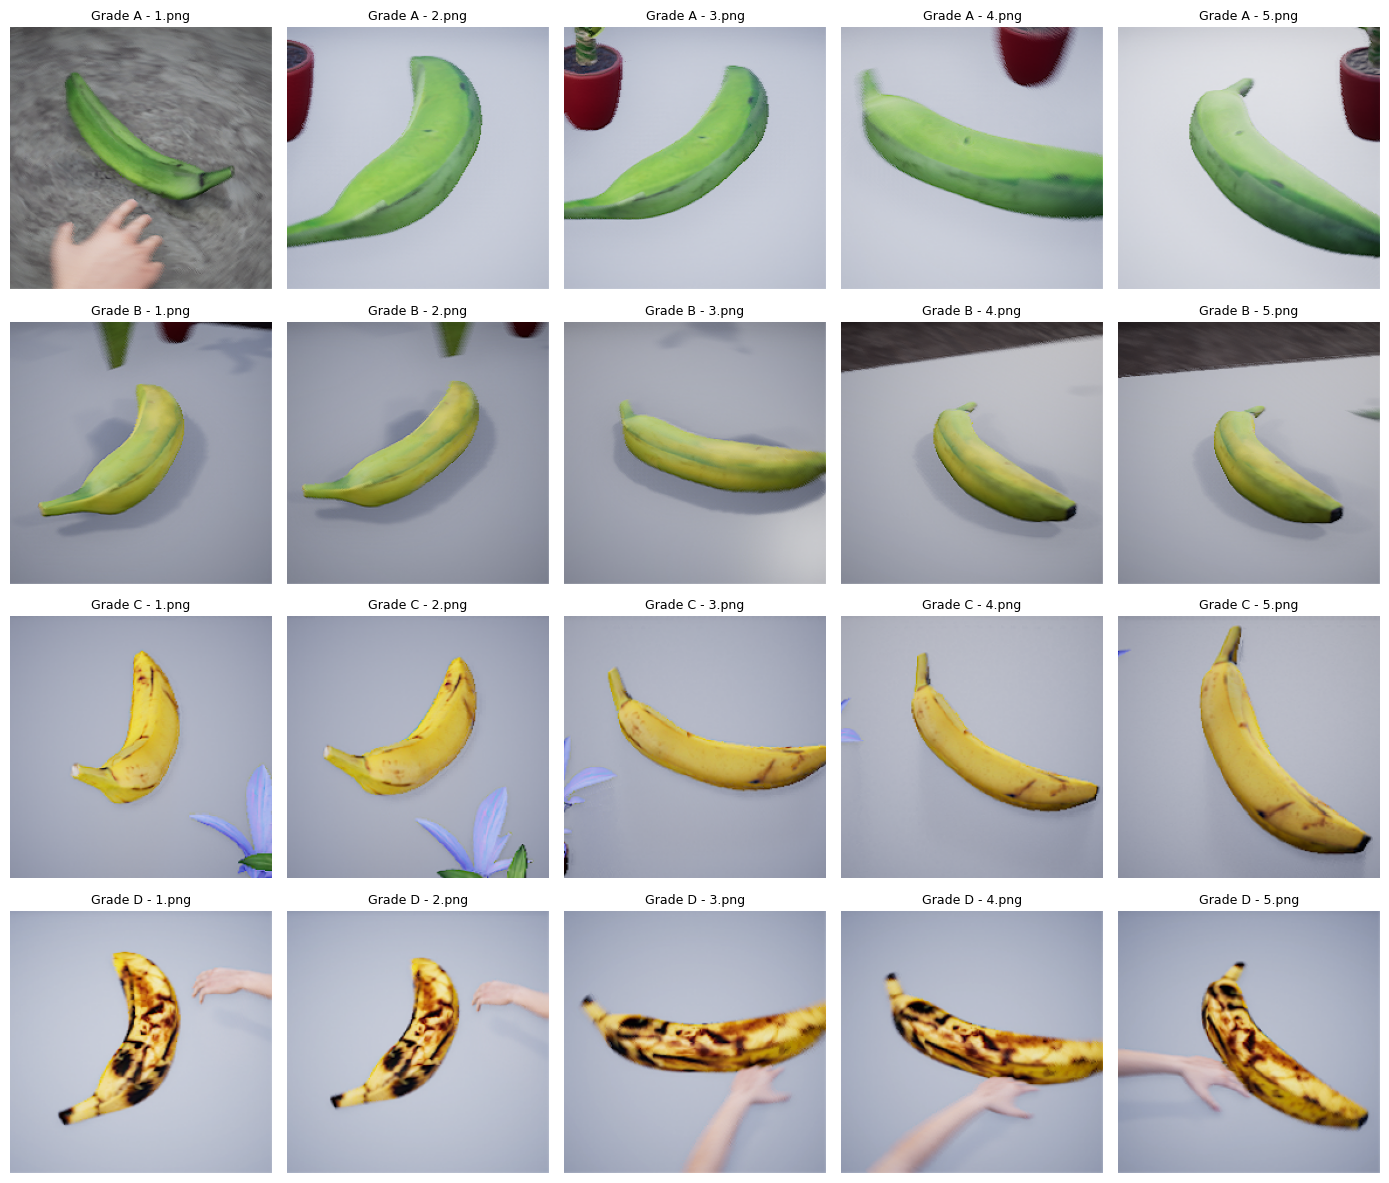

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

folder_dataset = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Dataset Pisang 200 Gambar"
)

kelas = ["Grade A", "Grade B", "Grade C", "Grade D"]

fig, axes = plt.subplots(4, 5, figsize=(14, 12))

for baris, nama_kelas in enumerate(kelas):
    folder_kelas = os.path.join(folder_dataset, nama_kelas)

    for kolom in range(5):
        nomor = kolom + 1
        path_gambar = os.path.join(
            folder_kelas, f"{nomor}.png"
        )

        ax = axes[baris, kolom]

        if os.path.isfile(path_gambar):
            img = Image.open(path_gambar).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"{nama_kelas} - {nomor}.png", fontsize=9)
        else:
            ax.set_title("Gambar tidak ditemukan", fontsize=8)

        ax.axis("off")

plt.tight_layout()
plt.show()


Langkah 10 — Membagi dataset menjadi training dan testing

In [ ]:
import os
import shutil
import random

random.seed(42)

folder_asal = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Dataset Pisang 200 Gambar"
)

folder_hasil = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Dataset Pisang Split"
)

kelas = ["Grade A", "Grade B", "Grade C", "Grade D"]
ekstensi = (".png", ".jpg", ".jpeg")

# Pastikan dataset asli tersedia
assert os.path.isdir(folder_asal), "Folder dataset asli tidak ditemukan!"

# Hapus hanya folder hasil pembagian sebelumnya
if os.path.exists(folder_hasil):
    shutil.rmtree(folder_hasil)

for bagian in ["train", "test"]:
    for nama_kelas in kelas:
        os.makedirs(
            os.path.join(folder_hasil, bagian, nama_kelas),
            exist_ok=True
        )

for nama_kelas in kelas:
    folder_kelas = os.path.join(folder_asal, nama_kelas)

    gambar = sorted([
        f for f in os.listdir(folder_kelas)
        if f.lower().endswith(ekstensi)
    ])

    assert len(gambar) == 50, (
        f"{nama_kelas} memiliki {len(gambar)} gambar, bukan 50"
    )

    random.shuffle(gambar)

    # 40 gambar untuk training, 10 gambar untuk testing
    gambar_train = gambar[:40]
    gambar_test = gambar[40:]

    for nama_file in gambar_train:
        shutil.copy2(
            os.path.join(folder_kelas, nama_file),
            os.path.join(folder_hasil, "train", nama_kelas, nama_file)
        )

    for nama_file in gambar_test:
        shutil.copy2(
            os.path.join(folder_kelas, nama_file),
            os.path.join(folder_hasil, "test", nama_kelas, nama_file)
        )

    print(
        f"{nama_kelas}: {len(gambar_train)} training, "
        f"{len(gambar_test)} testing"
    )

print("\nPembagian dataset selesai!")
print("Lokasi:", folder_hasil)


Grade A: 40 training, 10 testing
Grade B: 40 training, 10 testing
Grade C: 40 training, 10 testing
Grade D: 40 training, 10 testing

Pembagian dataset selesai!
Lokasi: /content/drive/MyDrive/Dataset PBL/Dataset Pisang Split


Langkah 11 — Preprocessing dan memuat dataset

In [ ]:
import tensorflow as tf
import numpy as np
import os

folder_dataset = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Dataset Pisang Split"
)

ukuran_gambar = (128, 128)
batch_size = 16
seed = 42

# Memuat data training
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(folder_dataset, "train"),
    labels="inferred",
    label_mode="int",
    image_size=ukuran_gambar,
    batch_size=batch_size,
    shuffle=True,
    seed=seed
)

# Memuat data testing tanpa mengacak urutan
test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(folder_dataset, "test"),
    labels="inferred",
    label_mode="int",
    image_size=ukuran_gambar,
    batch_size=batch_size,
    shuffle=False
)

# Menyimpan urutan label kelas
nama_kelas = train_ds.class_names

print("\nUrutan kelas:", nama_kelas)
print("Jumlah kelas:", len(nama_kelas))

# Normalisasi piksel menjadi rentang 0–1
train_ds = train_ds.map(
    lambda gambar, label: (
        tf.cast(gambar, tf.float32) / 255.0,
        label
    )
)

test_ds = test_ds.map(
    lambda gambar, label: (
        tf.cast(gambar, tf.float32) / 255.0,
        label
    )
)

# Mengoptimalkan proses input data
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("\nPreprocessing selesai.")


Found 160 files belonging to 4 classes.
Found 40 files belonging to 4 classes.

Urutan kelas: ['Grade A', 'Grade B', 'Grade C', 'Grade D']
Jumlah kelas: 4

Preprocessing selesai.


Langkah 12 — Membangun arsitektur CNN

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Membuat arsitektur CNN
model = models.Sequential([
    # Input gambar 128 x 128 x 3
    layers.Input(shape=(128, 128, 3)),

    # Blok CNN 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Blok CNN 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Blok CNN 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Mengurangi jumlah parameter dibanding Flatten
    layers.GlobalAveragePooling2D(),

    # Klasifikasi
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4, activation="softmax")
])

# Menampilkan arsitektur model
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,764 (397.52 KB)

 Trainable params: 101,764 (397.52 KB)

 Non-trainable params: 0 (0.00 B)

Langkah 13 — Compile model CNN

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model berhasil di-compile.")
print("Optimizer : Adam")
print("Loss      : Sparse Categorical Crossentropy")
print("Metric    : Accuracy")


Model berhasil di-compile.
Optimizer : Adam
Loss      : Sparse Categorical Crossentropy
Metric    : Accuracy


Langkah 14 — Melatih model

In [ ]:
jumlah_epoch = 20

history = model.fit(
    train_ds,
    epochs=jumlah_epoch,
    verbose=1
)


Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 753ms/step - accuracy: 0.2625 - loss: 1.3887
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 500ms/step - accuracy: 0.2875 - loss: 1.3788
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 744ms/step - accuracy: 0.3625 - loss: 1.3571
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 504ms/step - accuracy: 0.4062 - loss: 1.2822
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 683ms/step - accuracy: 0.4938 - loss: 1.1519
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 516ms/step - accuracy: 0.5562 - loss: 1.0590
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 780ms/step - accuracy: 0.6062 - loss: 0.8978
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 504ms/step - accuracy: 0.6562 - loss: 0.7603
Epoch 9/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 501ms/step - accuracy: 0.7125 - loss: 0.7017
Epoch 10/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 672ms/step - accuracy: 0.6250 - loss: 0.8897
Epoch 11/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 532ms/step - accuracy: 0.6438 - loss: 0.7639
Epoch 12/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 499ms/st

Langkah 15 — Evaluasi menggunakan data testing

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print("\n===== HASIL EVALUASI TESTING =====")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")


3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - accuracy: 0.7750 - loss: 0.4365

===== HASIL EVALUASI TESTING =====
Test Loss     : 0.4365
Test Accuracy : 77.50%


Langkah 16 — Membuat confusion matrix dan classification report

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 158ms/step


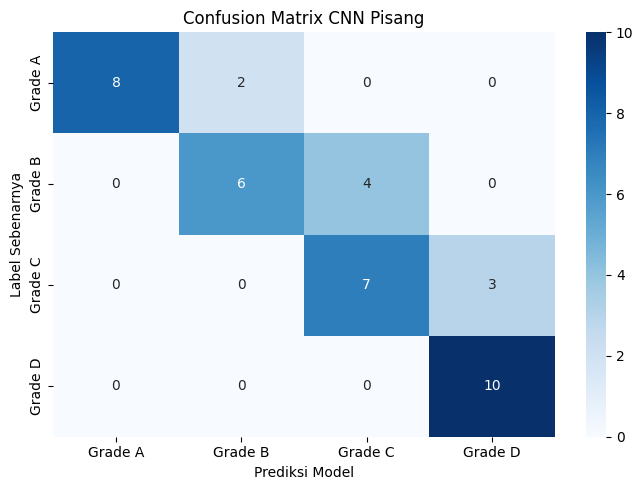


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

     Grade A     1.0000    0.8000    0.8889        10
     Grade B     0.7500    0.6000    0.6667        10
     Grade C     0.6364    0.7000    0.6667        10
     Grade D     0.7692    1.0000    0.8696        10

    accuracy                         0.7750        40
   macro avg     0.7889    0.7750    0.7729        40
weighted avg     0.7889    0.7750    0.7729        40



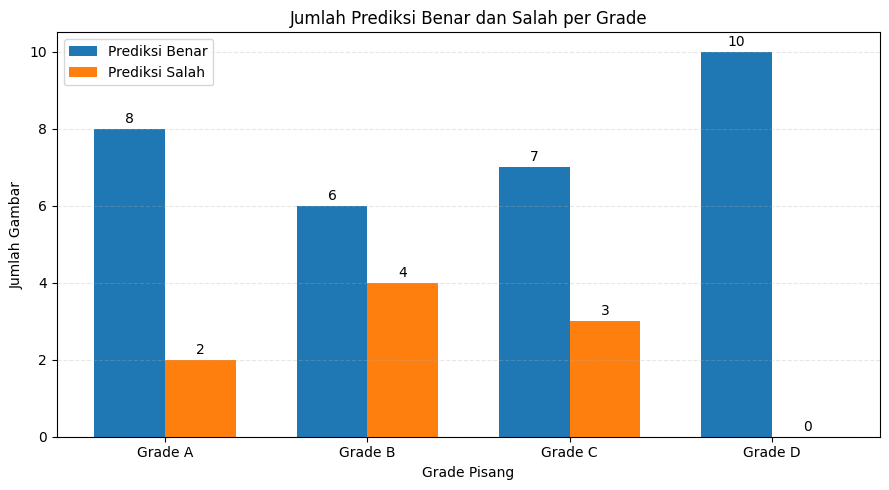

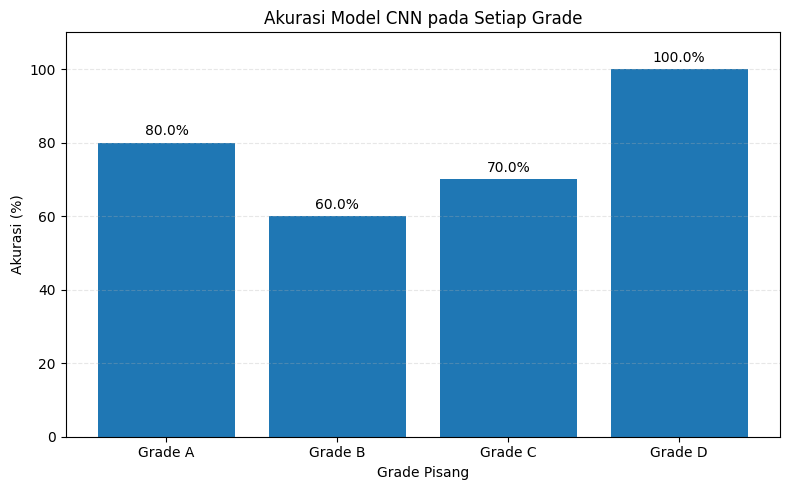

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# 1. Tetapkan nama kelas secara eksplisit
nama_kelas = ['Grade A', 'Grade B', 'Grade C', 'Grade D']

# 2. Mengambil label asli dan prediksi model
y_true = np.concatenate([
    label.numpy() for gambar, label in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Pastikan jumlah kelas sesuai dengan output model
assert y_prob.shape[1] == len(nama_kelas), \
    "Jumlah output model tidak sesuai dengan jumlah kelas!"

# 3. Membuat confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nama_kelas,
    yticklabels=nama_kelas
)

plt.xlabel("Prediksi Model")
plt.ylabel("Label Sebenarnya")
plt.title("Confusion Matrix CNN Pisang")
plt.tight_layout()
plt.show()

# 4. Classification report
print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=nama_kelas,
    zero_division=0,
    digits=4
))

# 5. Grafik batang: prediksi benar dan salah per grade
jumlah_benar = np.diag(cm)
jumlah_salah = cm.sum(axis=1) - jumlah_benar

x = np.arange(len(nama_kelas))
lebar = 0.35

plt.figure(figsize=(9, 5))

batang_benar = plt.bar(
    x - lebar / 2,
    jumlah_benar,
    lebar,
    label="Prediksi Benar"
)

batang_salah = plt.bar(
    x + lebar / 2,
    jumlah_salah,
    lebar,
    label="Prediksi Salah"
)

plt.bar_label(batang_benar, padding=2)
plt.bar_label(batang_salah, padding=2)

plt.xlabel("Grade Pisang")
plt.ylabel("Jumlah Gambar")
plt.title("Jumlah Prediksi Benar dan Salah per Grade")
plt.xticks(x, nama_kelas)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

# 6. Grafik batang: akurasi setiap grade
total_per_grade = cm.sum(axis=1)

akurasi_grade = np.divide(
    jumlah_benar,
    total_per_grade,
    out=np.zeros(len(nama_kelas), dtype=float),
    where=total_per_grade != 0
) * 100

plt.figure(figsize=(8, 5))

batang = plt.bar(nama_kelas, akurasi_grade)

plt.bar_label(
    batang,
    labels=[f"{nilai:.1f}%" for nilai in akurasi_grade],
    padding=3
)

plt.xlabel("Grade Pisang")
plt.ylabel("Akurasi (%)")
plt.title("Akurasi Model CNN pada Setiap Grade")
plt.ylim(0, 110)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

Langkah 17 — Memastikan Gambar Training dan Testing Terpisah

In [ ]:
import os

folder_split = (
    "/content/drive/MyDrive/Dataset PBL/"
    "Dataset Pisang Split"
)

kelas = ["Grade A", "Grade B", "Grade C", "Grade D"]

semua_terpisah = True

for nama_kelas in kelas:
    folder_train = os.path.join(folder_split, "train", nama_kelas)
    folder_test = os.path.join(folder_split, "test", nama_kelas)

    gambar_train = {
        f for f in os.listdir(folder_train)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    gambar_test = {
        f for f in os.listdir(folder_test)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    }

    irisan = gambar_train.intersection(gambar_test)

    print(f"\n{nama_kelas}")
    print("Training:", len(gambar_train))
    print("Testing :", len(gambar_test))
    print("Nama file sama:", len(irisan))

    if irisan:
        semua_terpisah = False
        print("File yang sama:", sorted(irisan))

print("\nHASIL:", "TERPISAH" if semua_terpisah else "ADA NAMA FILE BERSAMA")



Grade A
Training: 40
Testing : 10
Nama file sama: 0

Grade B
Training: 40
Testing : 10
Nama file sama: 0

Grade C
Training: 40
Testing : 10
Nama file sama: 0

Grade D
Training: 40
Testing : 10
Nama file sama: 0

HASIL: TERPISAH


Langkah 18 — Visualisasi Akurasi dan Loss CNN

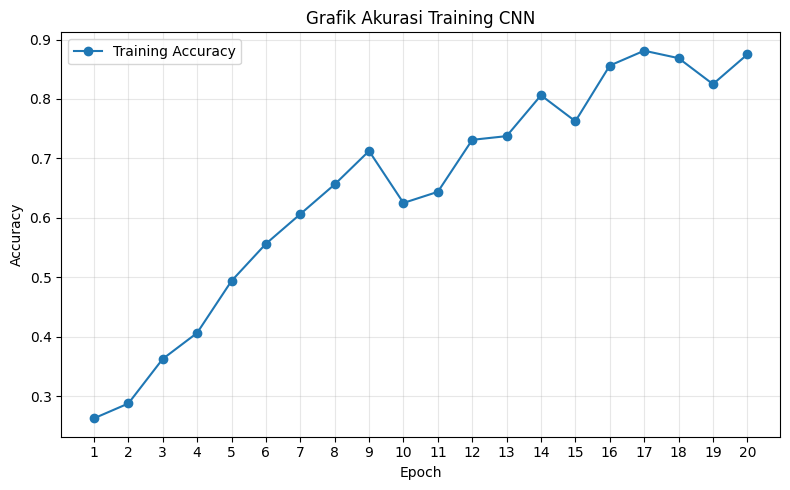

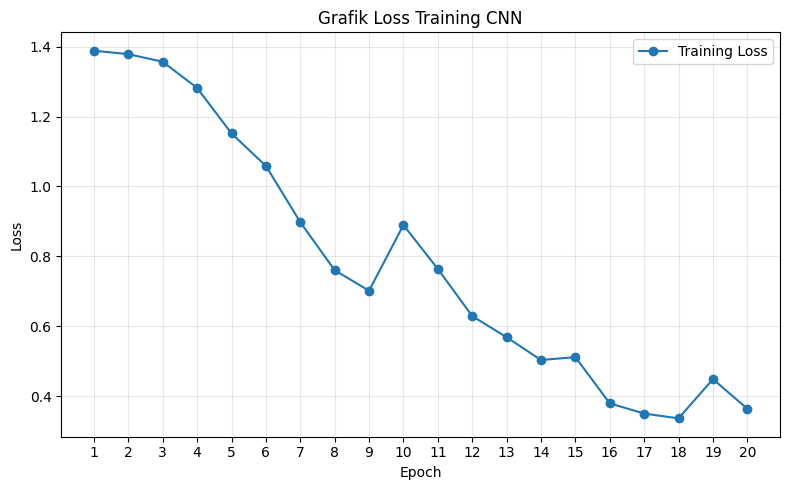

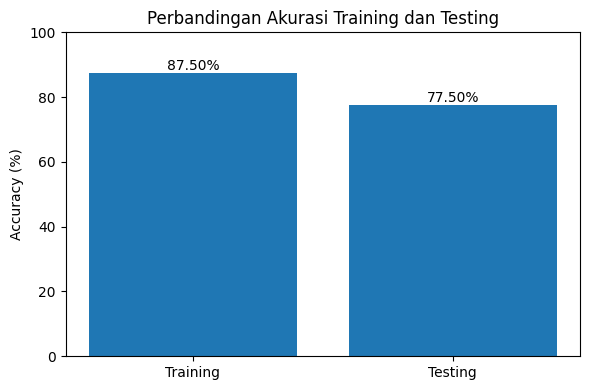

In [ ]:
import matplotlib.pyplot as plt

akurasi = history.history["accuracy"]
loss = history.history["loss"]
epoch = range(1, len(akurasi) + 1)

# Grafik akurasi
plt.figure(figsize=(8, 5))
plt.plot(epoch, akurasi, marker="o", label="Training Accuracy")
plt.title("Grafik Akurasi Training CNN")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(list(epoch))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Grafik loss
plt.figure(figsize=(8, 5))
plt.plot(epoch, loss, marker="o", label="Training Loss")
plt.title("Grafik Loss Training CNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(list(epoch))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Perbandingan akurasi akhir
plt.figure(figsize=(6, 4))
plt.bar(
    ["Training", "Testing"],
    [akurasi[-1] * 100, test_accuracy * 100]
)
plt.title("Perbandingan Akurasi Training dan Testing")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for i, nilai in enumerate(
    [akurasi[-1] * 100, test_accuracy * 100]
):
    plt.text(i, nilai + 1, f"{nilai:.2f}%", ha="center")

plt.tight_layout()
plt.show()
